In [1]:
import glob
import h5py
from tqdm import tqdm
import numpy as np
from matplotlib import pyplot as plt
import os

In [2]:
def read_files(glob_pattern, minyear=0, maxyear=9999):
    files = glob.glob(glob_pattern)
    angles = []

    for fpath in tqdm(files):
        year = int(os.path.basename(fpath)[:4])
        if year > maxyear:
            continue
        if year < minyear:
            continue

        hdf = h5py.File(fpath)
        angles.extend(hdf['angles_deg'][:].flatten())
        hdf.close()
    
    return np.array(angles)

In [3]:
angles_samples = read_files('../data/validation/angle_samples/*.hdf5')

100%|██████████████████████████████████████████████████████████████████████████████| 2748/2748 [00:11<00:00, 238.68it/s]


In [4]:
angles_testdata = read_files('../data/validation/angle_testdata/*.hdf5')

100%|██████████████████████████████████████████████████████████████████████████████| 5496/5496 [00:24<00:00, 221.76it/s]


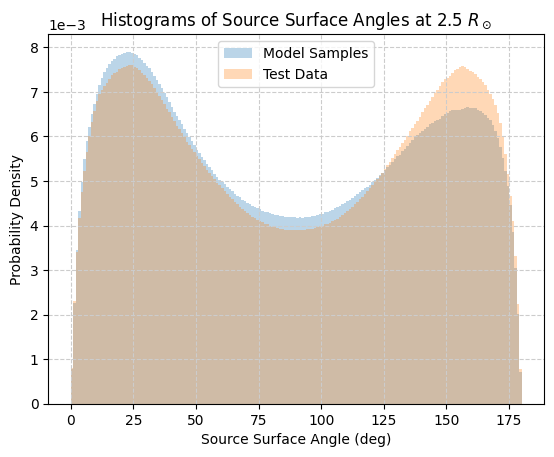

In [5]:
bins = np.arange(0, 181, 1)


plt.hist(angles_samples, bins=bins, label='Model Samples', density=True, alpha=0.3)
plt.hist(angles_testdata, bins=bins, label='Test Data', density=True, alpha=0.3)

plt.legend()
plt.ylabel('Probability Density')
plt.xlabel('Source Surface Angle (deg)')
plt.title(r'Histograms of Source Surface Angles at 2.5 $R_\odot$')
plt.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
plt.grid(linestyle='dashed', color='#ccc')
plt.savefig('../plots/paper/source_surf_angles_hist.png', dpi=300)

In [6]:
print('Samples')
print('---------')
print('Mean %.1f' % np.mean(angles_samples))
print('STD %.1f' % np.std(angles_samples))
print()
print('Test Data')
print('---------')
print('Mean %.1f'% np.mean(angles_testdata))
print('STD %.1f'%  np.std(angles_testdata))
print()

Samples
---------
Mean 87.2
STD 53.7

Test Data
---------
Mean 89.9
STD 54.4

